In [34]:
ls /global/cfs/cdirs/dune/www/data/2x2/nearline_run3/flowed_charge/Operations/20261102-LowIntensityBeam_LRSselfTrigger/packet-0070034-2026_11_02_11_48_40_CST.FLOW.hdf5

/global/cfs/cdirs/dune/www/data/2x2/nearline_run3/flowed_charge/Operations/20261102-LowIntensityBeam_LRSselfTrigger/packet-0070034-2026_11_02_11_48_40_CST.FLOW.hdf5


In [35]:
import h5py

In [36]:
with h5py.File('/global/cfs/cdirs/dune/www/data/2x2/nearline_run3/flowed_charge/Operations/20261102-LowIntensityBeam_LRSselfTrigger/packet-0070034-2026_11_02_11_48_40_CST.FLOW.hdf5', 'r') as f:
    print("Top-level keys:", list(f.keys()))

Top-level keys: ['analysis', 'charge', 'combined', 'geometry_info', 'lar_info', 'run_info']


In [37]:
file_path = ('/global/cfs/cdirs/dune/www/data/2x2/nearline_run3/flowed_charge/Operations/20261102-LowIntensityBeam_LRSselfTrigger/packet-0070034-2026_11_02_13_07_22_CST.FLOW.hdf5')

In [38]:
def print_hdf5_structure(name, obj):
    if isinstance(obj, h5py.Group):
        print(f"[GROUP]   {name}")
    elif isinstance(obj, h5py.Dataset):
        print(
            f"[DATASET] {name} | "
            f"Shape: {obj.shape} | "
            f"Type: {obj.dtype}"
        )

In [39]:
with h5py.File(file_path, 'r') as f:
    f.visititems(print_hdf5_structure)

[GROUP]   analysis
[GROUP]   analysis/rock_muon_segments
[DATASET] analysis/rock_muon_segments/data | Shape: (938,) | Type: [('rock_segment_id', '<i4'), ('x_start', '<f8'), ('y_start', '<f8'), ('z_start', '<f8'), ('dE', '<f8'), ('x_end', '<f8'), ('y_end', '<f8'), ('z_end', '<f8'), ('dQ', '<f8'), ('dx', '<f8'), ('x_mid', '<f8'), ('y_mid', '<f8'), ('z_mid', '<f8'), ('t', '<f8'), ('io_group', '<i4'), ('nhits', '<i4')]
[GROUP]   analysis/rock_muon_segments/ref
[GROUP]   analysis/rock_muon_segments/ref/analysis
[GROUP]   analysis/rock_muon_segments/ref/analysis/rock_muon_tracks
[DATASET] analysis/rock_muon_segments/ref/analysis/rock_muon_tracks/ref_region | Shape: (938,) | Type: [('start', '<i4'), ('stop', '<i4')]
[GROUP]   analysis/rock_muon_segments/ref/charge
[GROUP]   analysis/rock_muon_segments/ref/charge/calib_prompt_hits
[DATASET] analysis/rock_muon_segments/ref/charge/calib_prompt_hits/ref | Shape: (6221, 2) | Type: uint32
[DATASET] analysis/rock_muon_segments/ref/charge/calib_promp

In [40]:
# number of segments per track
import h5py
import numpy as np

with h5py.File(file_path, "r") as f:

    track_refs = f[
        "analysis/rock_muon_tracks/ref/"
        "analysis/rock_muon_segments/ref"
    ][:]

    track_regions = f[
        "analysis/rock_muon_tracks/ref/"
        "analysis/rock_muon_segments/ref_region"
    ][:]

    n_segments = track_regions["stop"] - track_regions["start"]

    print("Number of tracks:", len(n_segments))
    print("Total referenced segments:", np.sum(n_segments))
    print("Mean segments per track:", np.mean(n_segments))
    print("Minimum segments per track:", np.min(n_segments))
    print("Maximum segments per track:", np.max(n_segments))

    print("Segments per track:")
    print(n_segments)

Number of tracks: 45
Total referenced segments: 938
Mean segments per track: 20.844444444444445
Minimum segments per track: 1
Maximum segments per track: 64
Segments per track:
[ 1 46 62 62 64 26  4 59 13 13  2  4  4  4  4  9  3  4 61  2  4  4  4  4
  4 64  2  4 61  4  4  3 62  4 61  3  5  4  3  1 63  3  2 61 57]


Number of tracks: 45
Total referenced segments: 938
Mean segments per track: 20.844444444444445
Median segments per track: 4.0
Minimum: 1
Maximum: 64


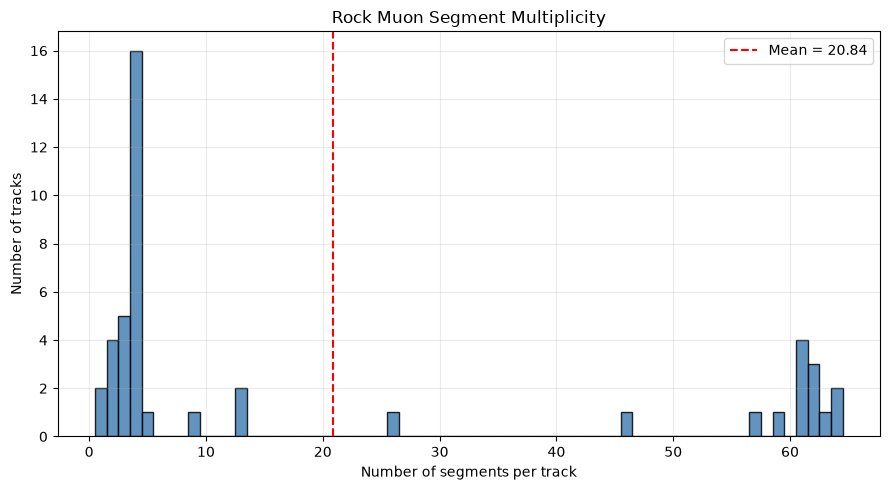

In [41]:
# plot segment per track distribution
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = (
    '/global/cfs/cdirs/dune/www/data/2x2/nearline_run3/'
    'flowed_charge/Operations/'
    '20261102-LowIntensityBeam_LRSselfTrigger/'
    'packet-0070034-2026_11_02_13_07_22_CST.FLOW.hdf5'
)

with h5py.File(file_path, 'r') as f:

    tracks = f['analysis/rock_muon_tracks/data'][:]

    regions = f[
        'analysis/rock_muon_tracks/ref/'
        'analysis/rock_muon_segments/ref_region'
    ][:]

    n_segments = regions['stop'] - regions['start']

print("Number of tracks:", len(tracks))
print("Total referenced segments:", n_segments.sum())
print("Mean segments per track:", n_segments.mean())
print("Median segments per track:", np.median(n_segments))
print("Minimum:", n_segments.min())
print("Maximum:", n_segments.max())

fig, ax = plt.subplots(figsize=(9, 5))

bins = np.arange(n_segments.min(), n_segments.max() + 2) - 0.5

ax.hist(n_segments, bins=bins, color='steelblue',
        edgecolor='black', alpha=0.85)

ax.axvline(n_segments.mean(), color='red', linestyle='--',
           label=f'Mean = {n_segments.mean():.2f}')

ax.set_xlabel('Number of segments per track')
ax.set_ylabel('Number of tracks')
ax.set_title('Rock Muon Segment Multiplicity')
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

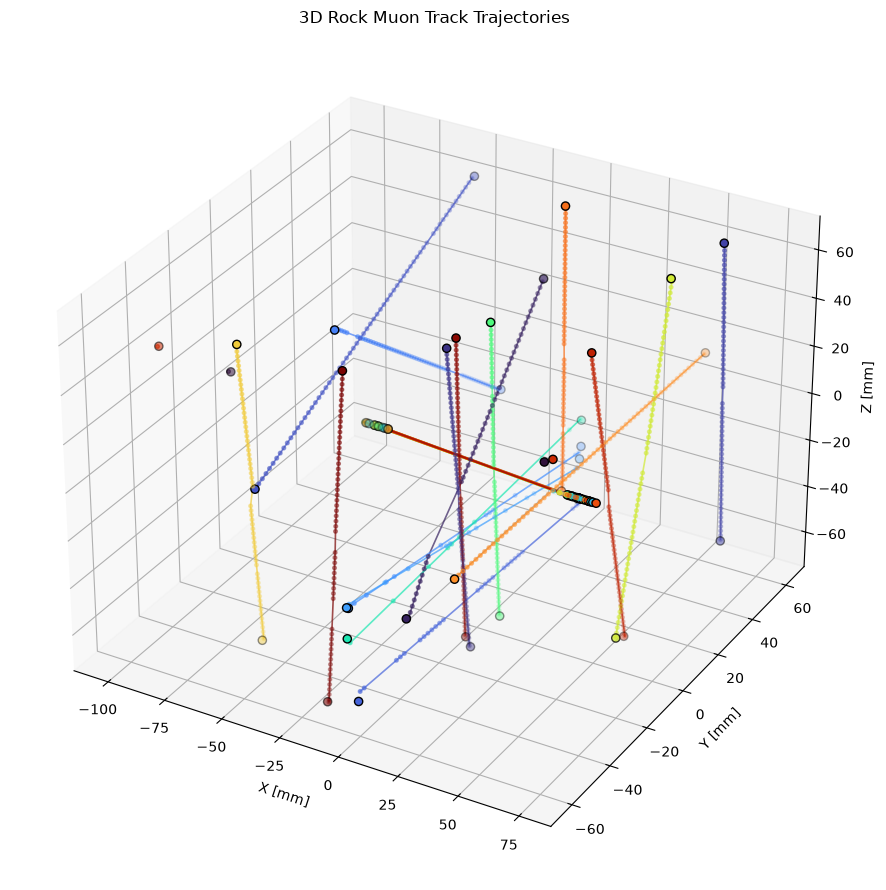

Number of tracks: 45
Number of segments: 938
Shape of seg_refs: (938, 2)
Number of track regions: 45
Track 0: start=0, stop=1, number of segments=1
Track 1: start=1, stop=47, number of segments=46
Track 2: start=47, stop=109, number of segments=62
Track 3: start=109, stop=171, number of segments=62
Track 4: start=171, stop=235, number of segments=64
Track 5: start=235, stop=261, number of segments=26
Track 6: start=261, stop=265, number of segments=4
Track 7: start=265, stop=324, number of segments=59
Track 8: start=324, stop=337, number of segments=13
Track 9: start=337, stop=350, number of segments=13
Track 10: start=350, stop=352, number of segments=2
Track 11: start=352, stop=356, number of segments=4
Track 12: start=356, stop=360, number of segments=4
Track 13: start=360, stop=364, number of segments=4
Track 14: start=364, stop=368, number of segments=4
Track 15: start=368, stop=377, number of segments=9
Track 16: start=377, stop=380, number of segments=3
Track 17: start=380, stop

In [51]:
# 3D tracks (and segments)
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File(file_path, 'r') as f:

    tracks = f['analysis/rock_muon_tracks/data'][:]
    segments = f['analysis/rock_muon_segments/data'][:]

    # Track-to-segment reference indices
    seg_refs = f[
        'analysis/rock_muon_tracks/ref/'
        'analysis/rock_muon_segments/ref'
    ][:]

    track_regions = f[
        'analysis/rock_muon_tracks/ref/'
        'analysis/rock_muon_segments/ref_region'
    ][:]

    # Read segment reference indices
    segment_indices = seg_refs[:, 1]

    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(111, projection='3d')

    colors = plt.cm.turbo(
        np.linspace(0, 1, len(tracks))
    )

    for i, (track, region) in enumerate(
        zip(tracks, track_regions)
    ):

        start = region['start']
        stop = region['stop']

        # Segment references belonging to this track
        refs = seg_refs[start:stop]

        # Each reference identifies a segment row.
        # Use the first column as the segment index.
        indices = refs[:, 1]

        track_segments = segments[indices]

        # Segment midpoints
        x = track_segments['x_mid']
        y = track_segments['y_mid']
        z = track_segments['z_mid']

        # Plot the reconstructed segment positions
        ax.scatter(x, y, z, color=colors[i], s=7, alpha=0.75)

        # Connect segment midpoints in reference order
        ax.plot(x, y, z, color=colors[i], linewidth=1.2, alpha=0.7)

        # Plot track start and end
        ax.scatter([track['x_start'], track['x_end']], [track['y_start'], track['y_end']], [track['z_start'], track['z_end']], color=[colors[i], colors[i]], marker='o', s=35, edgecolors='black')

    ax.set_xlabel('X [mm]')
    ax.set_ylabel('Y [mm]')
    ax.set_zlabel('Z [mm]')

    ax.set_title('3D Rock Muon Track Trajectories')

    plt.tight_layout()
    plt.savefig("segments_and_tracks_3d_display.png", dpi=300)
    plt.show()

print("Number of tracks:", len(tracks))
print("Number of segments:", len(segments))
print("Shape of seg_refs:", seg_refs.shape)
print("Number of track regions:", len(track_regions))

for i, region in enumerate(track_regions):
    start = region['start']
    stop = region['stop']

    print(
        f"Track {i}: "
        f"start={start}, "
        f"stop={stop}, "
        f"number of segments={stop-start}"
    )

for i, region in enumerate(track_regions[:5]):

    start = region['start']
    stop = region['stop']

    refs = seg_refs[start:stop]
    indices = refs[:, 0]

    track_segments = segments[indices]

    print(f"\nTrack {i}")
    print("X:", track_segments['x_mid'])
    print("Y:", track_segments['y_mid'])
    print("Z:", track_segments['z_mid'])

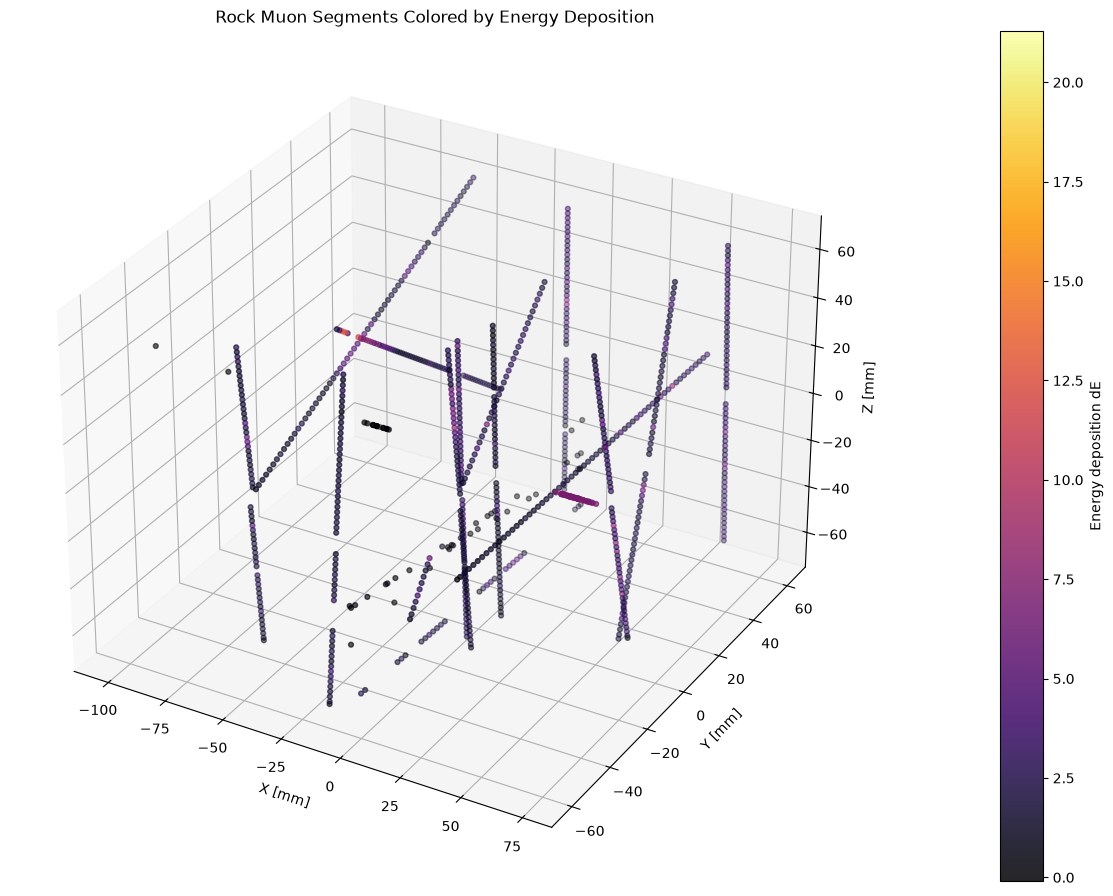

In [43]:
# 3D tracks by energy deposition
import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File(file_path, 'r') as f:

    segments = f['analysis/rock_muon_segments/data'][:]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

sc = ax.scatter(
    segments['x_mid'],
    segments['y_mid'],
    segments['z_mid'],
    c=segments['dE'],
    cmap='inferno',
    s=12,
    alpha=0.85
)

cbar = plt.colorbar(sc, ax=ax, pad=0.12)
cbar.set_label('Energy deposition dE')

ax.set_xlabel('X [mm]')
ax.set_ylabel('Y [mm]')
ax.set_zlabel('Z [mm]')
ax.set_title('Rock Muon Segments Colored by Energy Deposition')

plt.tight_layout()
plt.show()

In [44]:
# checking segments
with h5py.File(file_path, 'r') as f:

    segments = f['analysis/rock_muon_segments/data'][:]
    tracks = f['analysis/rock_muon_tracks/data'][:]
    seg_refs = f[
        'analysis/rock_muon_tracks/ref/'
        'analysis/rock_muon_segments/ref'
    ][:]

    print("Segment dtype:")
    print(segments.dtype)

    print("\nTrack dtype:")
    print(tracks.dtype)

    print("\nFirst 10 segments:")
    print(segments[:10])

    print("\nFirst 10 references:")
    print(seg_refs[:10])

Segment dtype:
[('rock_segment_id', '<i4'), ('x_start', '<f8'), ('y_start', '<f8'), ('z_start', '<f8'), ('dE', '<f8'), ('x_end', '<f8'), ('y_end', '<f8'), ('z_end', '<f8'), ('dQ', '<f8'), ('dx', '<f8'), ('x_mid', '<f8'), ('y_mid', '<f8'), ('z_mid', '<f8'), ('t', '<f8'), ('io_group', '<i4'), ('nhits', '<i4')]

Track dtype:
[('event_id', '<i4'), ('rock_muon_id', '<i4'), ('length', '<f8'), ('x_start', '<f8'), ('y_start', '<f8'), ('z_start', '<f8'), ('x_end', '<f8'), ('y_end', '<f8'), ('z_end', '<f8'), ('exp_var', '<f8'), ('PCA_i', '<f8'), ('PCA_j', '<f8'), ('PCA_k', '<f8'), ('a2a', '?', (4,)), ('a2c', '?', (4, 2))]

First 10 segments:
[(0, -67.74294024, -43.23149872, 43.91989899, 0.1842803 , -69.74294024, -43.23149872, 43.91989899,  5.4754636 , 2., -68.74294024, -43.23149872, 43.91989899, 8318. , 1, 1)
 (1,  14.33073805,  16.23185723, 64.26938728, 1.99390824,  14.44415862,  14.86318674, 62.81546952, 59.2443799 , 2.,  14.38744834,  15.54752198, 63.5424284 ,  725. , 2, 6)
 (2,  14.44415862,

In [45]:
# checking segments (2)
for i, region in enumerate(track_regions[:10]):

    start = region['start']
    stop = region['stop']

    indices = seg_refs[start:stop, 0]
    track_segments = segments[indices]

    xyz = np.column_stack([
        track_segments['x_mid'],
        track_segments['y_mid'],
        track_segments['z_mid']
    ])

    print(f"\nTrack {i}")
    print("Number of segments:", len(xyz))
    print("Unique positions:", len(np.unique(xyz, axis=0)))
    print("Coordinate range:", np.ptp(xyz, axis=0))


Track 0
Number of segments: 1
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 1
Number of segments: 46
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 2
Number of segments: 62
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 3
Number of segments: 62
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 4
Number of segments: 64
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 5
Number of segments: 26
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 6
Number of segments: 4
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 7
Number of segments: 59
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 8
Number of segments: 13
Unique positions: 1
Coordinate range: [0. 0. 0.]

Track 9
Number of segments: 13
Unique positions: 1
Coordinate range: [0. 0. 0.]


In [49]:
# check refereneces
print("First 20 segment references:")
print(seg_refs[:20])

print("\nFirst 20 segment indices:")
print(seg_refs[:20, 0])

print("\nFirst 20 segment coordinates:")

for idx in seg_refs[:20, 0]:
    print(
        idx,
        segments[idx]['x_mid'],
        segments[idx]['y_mid'],
        segments[idx]['z_mid']
    )

First 20 segment references:
[[ 0  0]
 [ 1  1]
 [ 1  2]
 [ 1  3]
 [ 1  4]
 [ 1  5]
 [ 1  6]
 [ 1  7]
 [ 1  8]
 [ 1  9]
 [ 1 10]
 [ 1 11]
 [ 1 12]
 [ 1 13]
 [ 1 14]
 [ 1 15]
 [ 1 16]
 [ 1 17]
 [ 1 18]
 [ 1 19]]

First 20 segment indices:
[0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

First 20 segment coordinates:
0 -68.74294024414061 -43.23149871826172 43.919898986816406
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840229765
1 14.387448335541139 15.547521983001797 63.54242840

In [47]:
print("Using column 0:")
print(seg_refs[:20, 0])

print("\nUsing column 1:")
print(seg_refs[:20, 1])

print("\nCoordinates using column 1:")

for idx in seg_refs[:20, 1]:
    print(
        idx,
        segments[idx]['x_mid'],
        segments[idx]['y_mid'],
        segments[idx]['z_mid']
    )

Using column 0:
[0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Using column 1:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]

Coordinates using column 1:
0 -68.74294024414061 -43.23149871826172 43.919898986816406
1 14.387448335541139 15.547521983001797 63.54242840229765
2 14.500868909794262 14.178851492190908 62.08851063952027
3 14.614289484047383 12.81018100138002 60.6345928767429
4 14.727710058300506 11.441510510569127 59.18067511396553
5 14.841130632553627 10.072840019758239 57.72675735118815
6 14.95455120680675 8.70416952894735 56.27283958841077
7 15.067971781059873 7.33549903813646 54.818921825633396
8 15.181392355312994 5.966828547325571 53.36500406285602
9 15.294812929566117 4.598158056514681 51.911086300078644
10 15.408233503819238 3.22948756570379 50.457168537301264
11 15.52165407807236 1.8608170748929012 49.00325077452389
12 15.635074652325484 0.4921465840820106 47.54933301174652
13 15.748495226578605 -0.8765239067288798 46.09541524896914
14 15.861915800831728 -2.